# Interferon-beta response in human PBMCs at single-cell resolution

**Author:** Patricia K. Kamanda

Kang and colleagues (2018) stimulated peripheral blood mononuclear cells (PBMCs) from lupus patients with interferon-beta (IFN-beta) and profiled stimulated and control cells with droplet single-cell RNA sequencing (GEO GSE96583). This notebook analyses the subset of that study distributed with the Bioconductor package muscat: two donors, each contributing a control and a stimulated sample, 1,556 cells and 1,267 genes in all. The analysis has two goals:

1. **Recover cell identities** from the data alone. Stimulation reprograms gene expression so strongly that, without correction, cells separate by condition rather than by type; the analysis integrates the samples with Harmony before clustering, then checks the result against the authors' annotations.
2. **Measure the interferon response in each cell type** with a pseudobulk differential expression analysis that respects the paired, multi-donor design, rather than treating individual cells as independent replicates.

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import scipy.io
import scanpy as sc
import anndata as ad
import harmonypy
import matplotlib.pyplot as plt
from sklearn.metrics import adjusted_rand_score
from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats
from pydeseq2.default_inference import DefaultInference

ROOT = Path("..") if Path("../data").exists() else Path(".")
FIG = ROOT / "results" / "figures"
TAB = ROOT / "results" / "tables"
FIG.mkdir(parents=True, exist_ok=True)
TAB.mkdir(parents=True, exist_ok=True)
sc.settings.verbosity = 0
sc.settings.set_figure_params(dpi=100, dpi_save=150, frameon=False, figsize=(4.5, 4))
SEED = 20261117

## Load the data

In [2]:
counts = scipy.io.mmread(ROOT / "data" / "counts.mtx.gz").T.tocsr()      # cells x genes
genes = pd.read_csv(ROOT / "data" / "genes.csv")
cells = pd.read_csv(ROOT / "data" / "cells.csv").set_index("barcode")

adata = ad.AnnData(X=counts.astype(np.float32), obs=cells, var=genes.set_index("symbol"))
adata.layers["counts"] = adata.X.copy()
adata.obs["condition"] = pd.Categorical(adata.obs["condition"], categories=["control", "IFN-beta"])
adata

AnnData object with n_obs × n_vars = 1556 × 1267
    obs: 'sample', 'donor', 'condition', 'author_cell_type'
    var: 'ensembl'
    layers: None (.X), 'counts'

In [3]:
pd.crosstab(adata.obs["sample"], adata.obs["author_cell_type"], margins=True)

author_cell_type,B cells,CD14+ Monocytes,CD4 T cells,CD8 T cells,FCGR3A+ Monocytes,All
sample,,,,,,
ctrl101,100,100,100,74,80,454
ctrl107,44,100,100,20,32,296
stim101,100,100,100,100,100,500
stim107,54,100,100,15,37,306
All,298,400,400,209,249,1556


## Quality control

The distributed subset has already been filtered by the muscat authors, so the checks here confirm that no sample is dominated by low-complexity or unusually large barcodes rather than imposing new thresholds.

In [4]:
sc.pp.calculate_qc_metrics(adata, inplace=True, percent_top=None, log1p=False)
qc = adata.obs.groupby("sample")[["total_counts", "n_genes_by_counts"]].median().round(0)
qc.columns = ["median UMIs per cell", "median genes per cell"]
qc

,median UMIs per cell,median genes per cell
sample,,
ctrl101,1024.0,314.0
ctrl107,1216.0,321.0
stim101,1101.0,339.0
stim107,1206.0,344.0


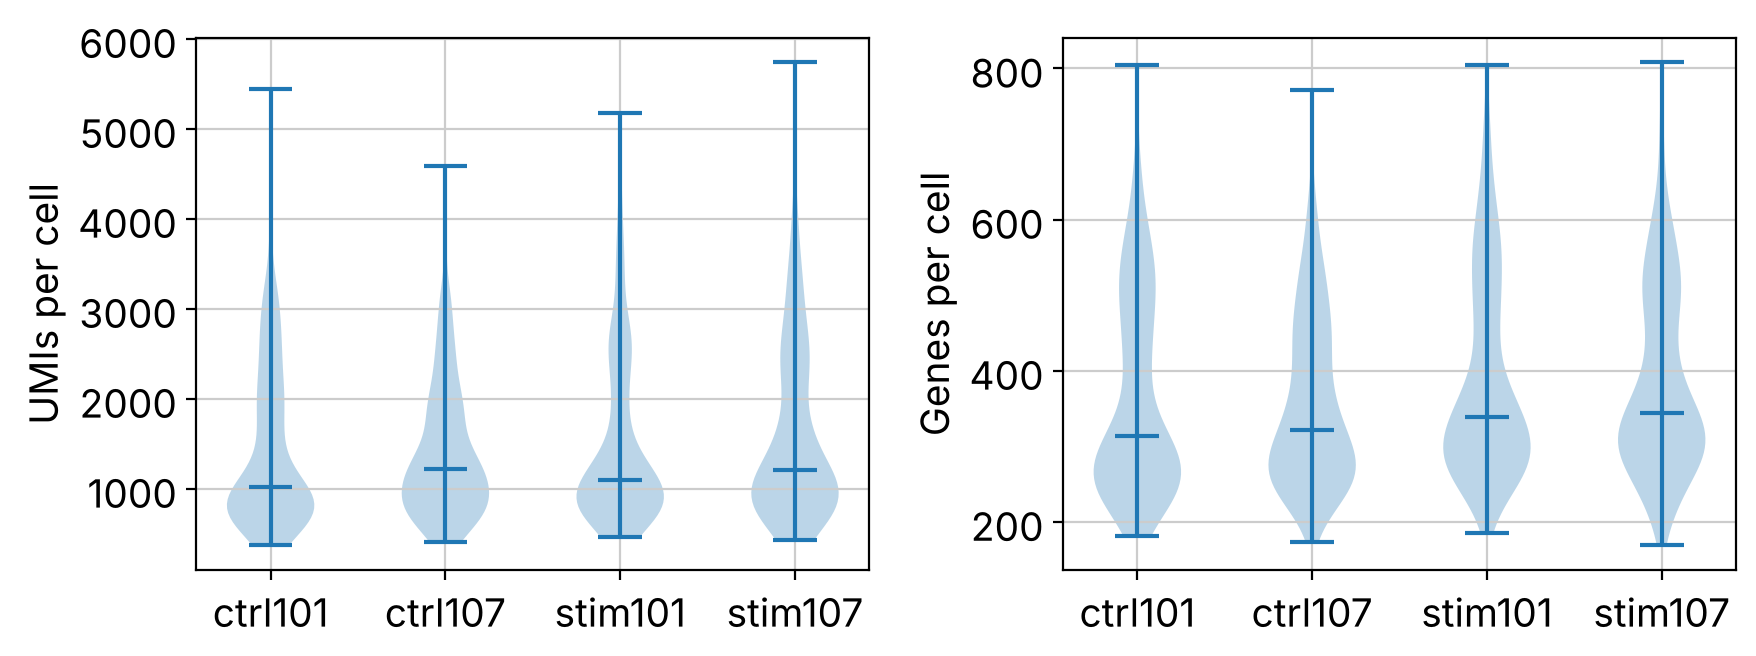

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
for ax, col, label in zip(axes, ["total_counts", "n_genes_by_counts"], ["UMIs per cell", "Genes per cell"]):
    data = [adata.obs.loc[adata.obs["sample"] == s, col] for s in sorted(adata.obs["sample"].unique())]
    ax.violinplot(data, showmedians=True)
    ax.set_xticks(range(1, len(data) + 1), sorted(adata.obs["sample"].unique()))
    ax.set_ylabel(label)
plt.tight_layout()
plt.savefig(FIG / "qc_violins.png", dpi=150)
plt.show()

In [6]:
before = adata.n_obs
sc.pp.filter_cells(adata, min_genes=50)
sc.pp.filter_genes(adata, min_cells=5)
print(f"Kept {adata.n_obs} of {before} cells and {adata.n_vars} genes.")

Kept 1556 of 1556 cells and 1267 genes.


## Normalization, feature selection, and dimensionality reduction

In [7]:
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
sc.pp.highly_variable_genes(adata, layer="counts", flavor="seurat_v3", n_top_genes=600, batch_key="sample")
sc.pp.scale(adata, max_value=10)
sc.tl.pca(adata, n_comps=30, mask_var="highly_variable", random_state=SEED)

### Without integration, cells separate by condition

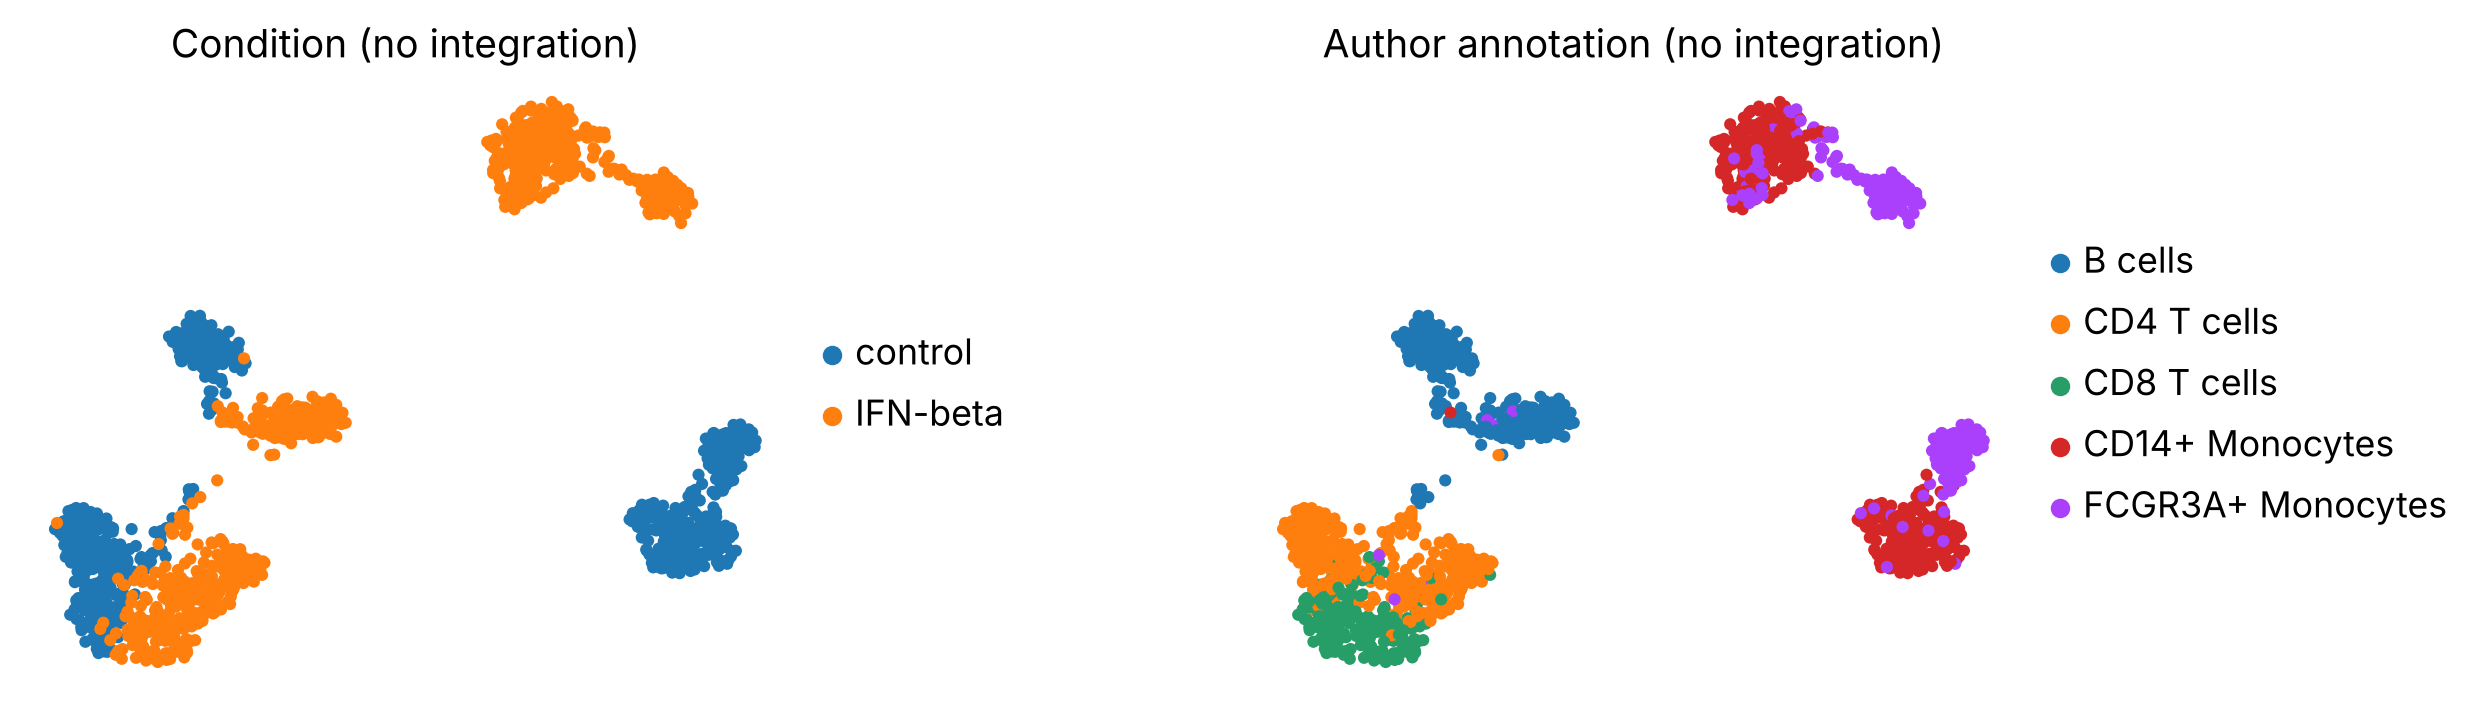

In [8]:
sc.pp.neighbors(adata, n_neighbors=15, n_pcs=20, random_state=SEED)
sc.tl.umap(adata, random_state=SEED)
adata.obsm["X_umap_uncorrected"] = adata.obsm["X_umap"].copy()
sc.pl.embedding(adata, basis="X_umap_uncorrected", color=["condition", "author_cell_type"], wspace=0.45,
                title=["Condition (no integration)", "Author annotation (no integration)"], show=False)
plt.savefig(FIG / "umap_uncorrected.png", dpi=150, bbox_inches="tight")
plt.show()

### Harmony integration across samples

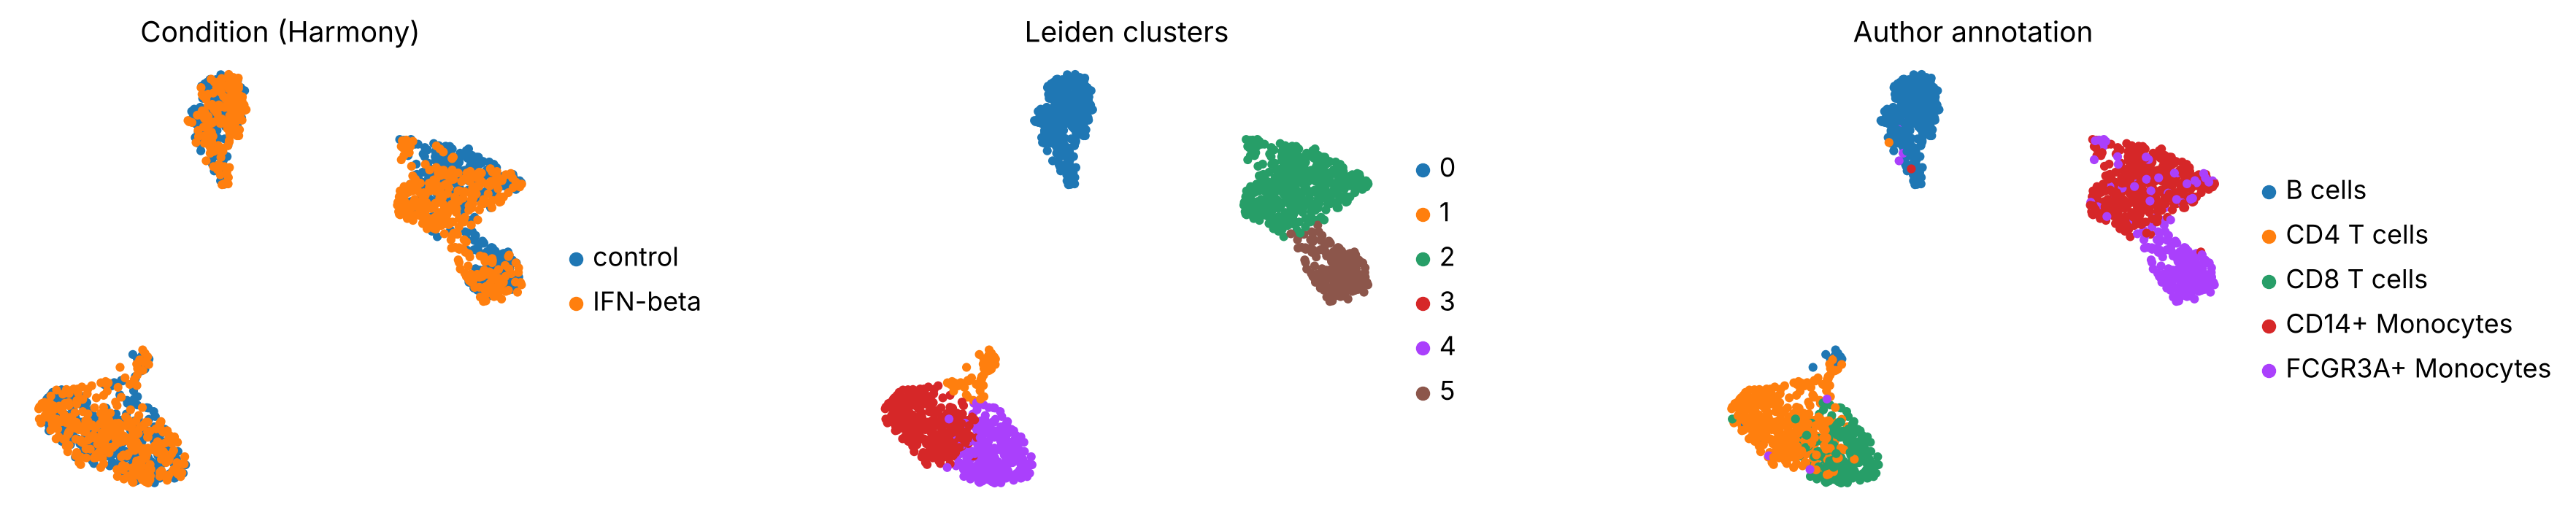

In [9]:
ho = harmonypy.run_harmony(adata.obsm["X_pca"][:, :20], adata.obs, "sample", random_state=SEED, verbose=False)
z = np.asarray(ho.Z_corr)
adata.obsm["X_pca_harmony"] = z.T if z.shape[0] != adata.n_obs else z
sc.pp.neighbors(adata, n_neighbors=15, use_rep="X_pca_harmony", random_state=SEED)
sc.tl.umap(adata, random_state=SEED)
sc.tl.leiden(adata, resolution=0.4, random_state=SEED, flavor="igraph", n_iterations=2, directed=False)
sc.pl.umap(adata, color=["condition", "leiden", "author_cell_type"], wspace=0.45, show=False,
           title=["Condition (Harmony)", "Leiden clusters", "Author annotation"])
plt.savefig(FIG / "umap_harmony.png", dpi=150, bbox_inches="tight")
plt.show()

## Cell type annotation from canonical markers

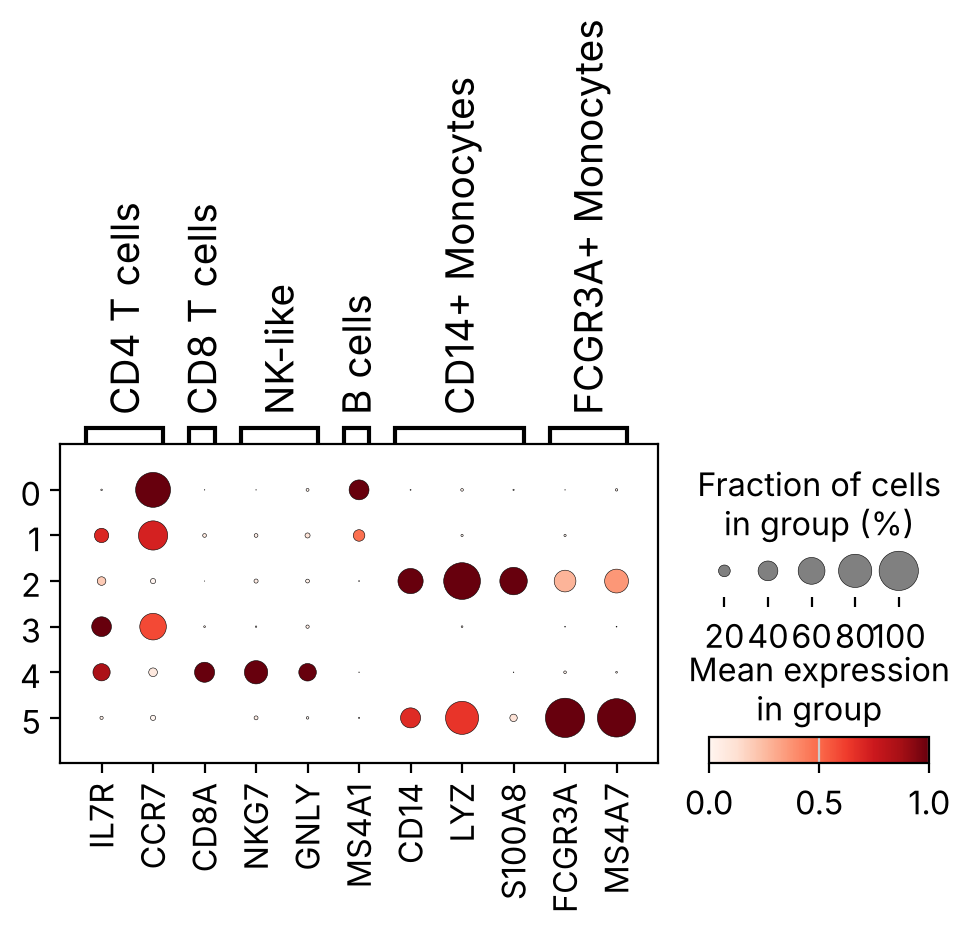

In [10]:
markers = {
    "CD4 T cells": ["IL7R", "CCR7"],
    "CD8 T cells": ["CD8A", "CD8B"],
    "NK-like": ["NKG7", "GNLY"],
    "B cells": ["MS4A1", "CD79B"],
    "CD14+ Monocytes": ["CD14", "LYZ", "S100A8"],
    "FCGR3A+ Monocytes": ["FCGR3A", "MS4A7"],
}
markers = {k: [g for g in v if g in adata.var_names] for k, v in markers.items()}
sc.pl.dotplot(adata, markers, groupby="leiden", standard_scale="var", show=False)
plt.savefig(FIG / "marker_dotplot.png", dpi=150, bbox_inches="tight")
plt.show()

In [11]:
# Score each cluster against each marker set and assign the best-scoring cell type
for cell_type, genes_ in markers.items():
    sc.tl.score_genes(adata, genes_, score_name=f"score_{cell_type}", random_state=SEED)
score_cols = [f"score_{c}" for c in markers]
cluster_scores = adata.obs.groupby("leiden")[score_cols].mean()
assignment = cluster_scores.idxmax(axis=1).str.replace("score_", "", regex=False)
adata.obs["cell_type"] = adata.obs["leiden"].map(assignment).astype("category")
assignment.rename("assigned cell type").to_frame()

,assigned cell type
leiden,
0,B cells
1,CD4 T cells
2,CD14+ Monocytes
3,CD4 T cells
4,CD8 T cells
5,FCGR3A+ Monocytes


In [12]:
agreement = pd.crosstab(adata.obs["author_cell_type"], adata.obs["cell_type"])
ari = adjusted_rand_score(adata.obs["author_cell_type"], adata.obs["cell_type"])
agreement.to_csv(TAB / "annotation_agreement.csv")
print(f"Adjusted Rand index against the author annotation: {ari:.2f}")
agreement

Adjusted Rand index against the author annotation: 0.80


cell_type,B cells,CD14+ Monocytes,CD4 T cells,CD8 T cells,FCGR3A+ Monocytes
author_cell_type,,,,,
B cells,285,0,13,0,0
CD4 T cells,1,0,342,57,0
CD8 T cells,0,0,12,197,0
CD14+ Monocytes,1,397,0,0,2
FCGR3A+ Monocytes,3,51,2,1,192


The data-driven annotation agrees well with the published labels (adjusted Rand index 0.80). The disagreements fall where they would be expected with only 1,267 genes: some CD4 T cells are assigned to the CD8 cluster, and some FCGR3A+ monocytes to the CD14+ monocyte cluster, two pairs of populations that differ by a handful of markers. No cluster is assigned to the NK marker set, consistent with the five cell types present in this subset. The differential expression analysis below therefore uses the authors' labels, which were defined with the full transcriptome, while the clustering serves as an independent check that the main populations are recoverable from the data alone.

## Interferon response score

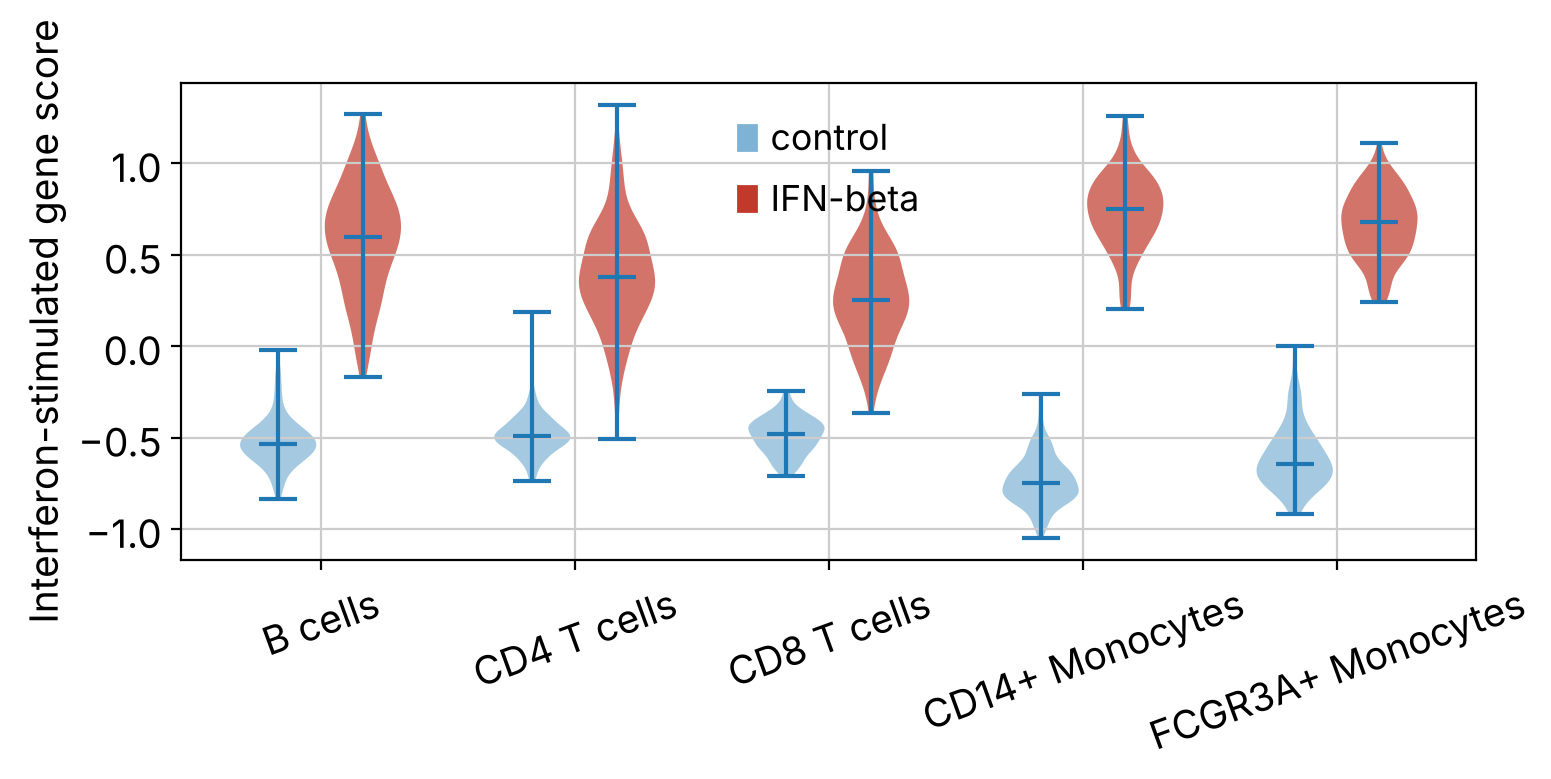

In [13]:
isgs = ["ISG15", "IFI6", "IFIT1", "IFIT2", "IFIT3", "MX1", "MX2", "OAS1", "OAS2", "ISG20",
        "IFITM3", "IRF7", "STAT1", "RSAD2", "IFI44L", "XAF1", "LY6E", "CXCL10"]
isgs = [g for g in isgs if g in adata.var_names]
sc.tl.score_genes(adata, isgs, score_name="isg_score", random_state=SEED)
fig, ax = plt.subplots(figsize=(8, 3.8))
types = list(adata.obs["author_cell_type"].cat.categories) if hasattr(adata.obs["author_cell_type"], "cat") else sorted(adata.obs["author_cell_type"].unique())
pos, data, colours = [], [], []
for i, t in enumerate(types):
    for j, cond in enumerate(["control", "IFN-beta"]):
        sel = (adata.obs["author_cell_type"] == t) & (adata.obs["condition"] == cond)
        data.append(adata.obs.loc[sel, "isg_score"].values)
        pos.append(i * 3 + j)
        colours.append("#7FB3D5" if cond == "control" else "#C0392B")
parts = ax.violinplot(data, positions=pos, showmedians=True, widths=0.9)
for body, colour in zip(parts["bodies"], colours):
    body.set_facecolor(colour)
    body.set_alpha(0.7)
ax.set_xticks([i * 3 + 0.5 for i in range(len(types))], types, rotation=20)
ax.set_ylabel("Interferon-stimulated gene score")
ax.legend([plt.Rectangle((0, 0), 1, 1, color="#7FB3D5"), plt.Rectangle((0, 0), 1, 1, color="#C0392B")],
          ["control", "IFN-beta"], frameon=False)
plt.tight_layout()
plt.savefig(FIG / "isg_score_by_cell_type.png", dpi=150)
plt.show()

## Pseudobulk differential expression by cell type

Cells from the same sample are not independent replicates, so counts are summed within each combination of sample and cell type, and the resulting pseudobulk profiles are compared with DESeq2 (PyDESeq2) using the paired design `~ donor + condition`. With two donors per condition each test has few residual degrees of freedom; strong, consistent responses are still detectable, and the result is honest about the evidence the design can provide.

In [14]:
def pseudobulk(adata, group_key, sample_key="sample", min_cells=10):
    rows, meta = [], []
    for (group, sample), idx in adata.obs.groupby([group_key, sample_key], observed=True).groups.items():
        if len(idx) < min_cells:
            continue
        rows.append(np.asarray(adata[idx].layers["counts"].sum(axis=0)).ravel())
        first = adata.obs.loc[idx[0]]
        meta.append({"cell_type": group, "sample": sample, "donor": first["donor"],
                     "condition": first["condition"], "n_cells": len(idx)})
    pb = pd.DataFrame(np.vstack(rows).round().astype(int), columns=adata.var_names)
    meta = pd.DataFrame(meta)
    pb.index = meta.index = meta["cell_type"].astype(str) + "|" + meta["sample"].astype(str)
    return pb, meta

pb_counts, pb_meta = pseudobulk(adata, "author_cell_type")
pb_meta

,cell_type,sample,donor,condition,n_cells
B cells|ctrl101,B cells,ctrl101,donor_101,control,100
B cells|ctrl107,B cells,ctrl107,donor_107,control,44
B cells|stim101,B cells,stim101,donor_101,IFN-beta,100
B cells|stim107,B cells,stim107,donor_107,IFN-beta,54
CD4 T cells|ctrl101,CD4 T cells,ctrl101,donor_101,control,100
CD4 T cells|ctrl107,CD4 T cells,ctrl107,donor_107,control,100
CD4 T cells|stim101,CD4 T cells,stim101,donor_101,IFN-beta,100
CD4 T cells|stim107,CD4 T cells,stim107,donor_107,IFN-beta,100
CD8 T cells|ctrl101,CD8 T cells,ctrl101,donor_101,control,74
CD8 T cells|ctrl107,CD8 T cells,ctrl107,donor_107,control,20


In [15]:
inference = DefaultInference(n_cpus=2)
results = []
for cell_type in pb_meta["cell_type"].unique():
    meta_ct = pb_meta[pb_meta["cell_type"] == cell_type].copy()
    if meta_ct["condition"].nunique() < 2 or meta_ct["donor"].nunique() < 2:
        continue
    counts_ct = pb_counts.loc[meta_ct.index]
    counts_ct = counts_ct.loc[:, counts_ct.sum(axis=0) >= 10]
    meta_ct["condition"] = pd.Categorical(meta_ct["condition"].astype(str), categories=["control", "IFN-beta"])
    dds = DeseqDataSet(counts=counts_ct, metadata=meta_ct[["donor", "condition"]],
                       design="~ donor + condition", refit_cooks=True, inference=inference, quiet=True)
    dds.deseq2()
    stats = DeseqStats(dds, contrast=["condition", "IFN-beta", "control"], inference=inference, quiet=True)
    stats.summary()
    res = stats.results_df.copy()
    res["cell_type"] = cell_type
    results.append(res.reset_index(names="gene"))

de = pd.concat(results, ignore_index=True)
de.to_csv(TAB / "pseudobulk_ifnb_vs_control_by_cell_type.csv", index=False)
summary = (de.assign(sig=de["padj"] < 0.05, up=(de["padj"] < 0.05) & (de["log2FoldChange"] > 0))
             .groupby("cell_type")[["sig", "up"]].sum()
             .rename(columns={"sig": "genes at FDR < 0.05", "up": "of which up"}))
summary["genes tested"] = de.groupby("cell_type").size()
summary.to_csv(TAB / "pseudobulk_summary.csv")
summary

,genes at FDR < 0.05,of which up,genes tested
cell_type,,,
B cells,35,35,1110
CD14+ Monocytes,337,253,1255
CD4 T cells,80,71,1109
CD8 T cells,13,13,1057
FCGR3A+ Monocytes,144,127,1249


### Shared and cell-type-specific responses

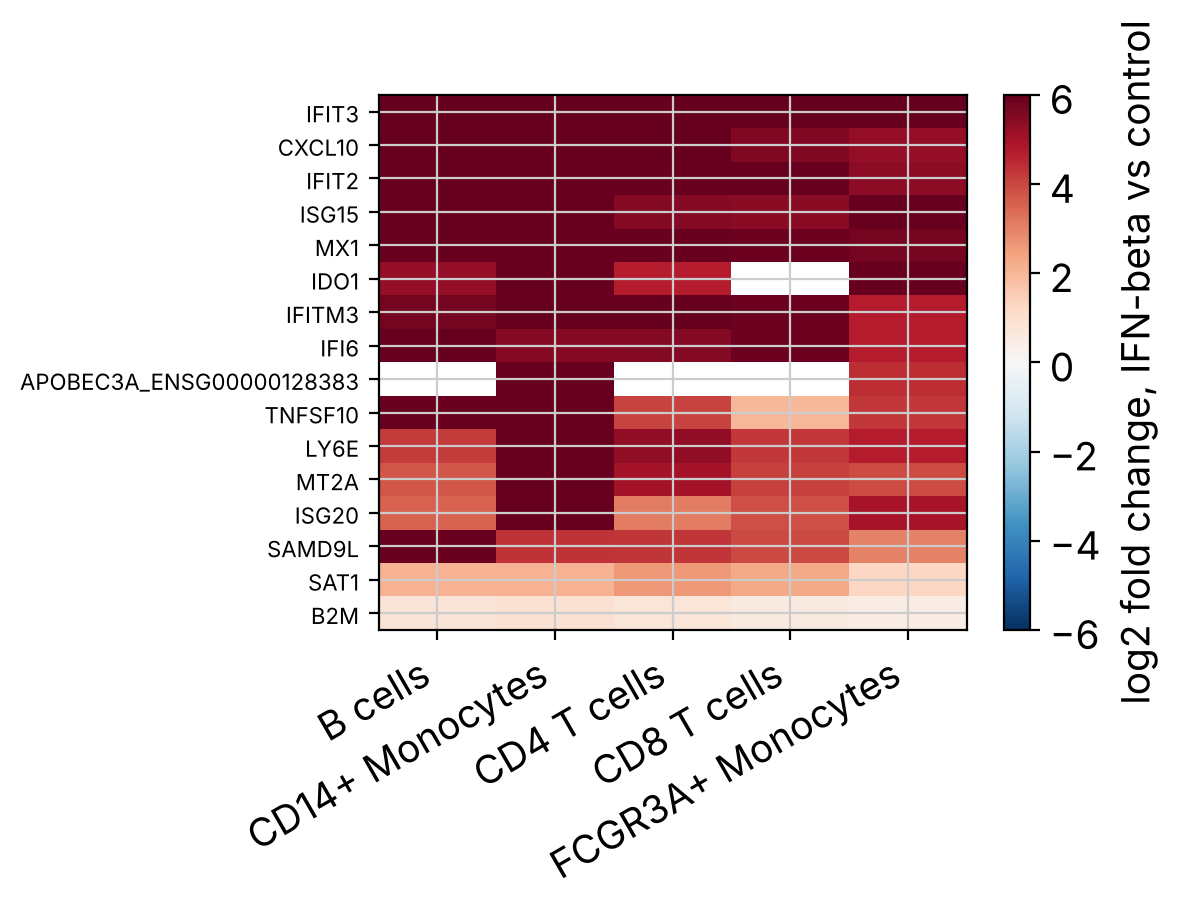

In [16]:
top_genes = (de[de["padj"] < 0.05].sort_values("padj").groupby("cell_type").head(8)["gene"].unique())
lfc = de[de["gene"].isin(top_genes)].pivot(index="gene", columns="cell_type", values="log2FoldChange")
lfc = lfc.loc[lfc.mean(axis=1).sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(6, max(4, 0.28 * len(lfc))))
im = ax.imshow(lfc.values, cmap="RdBu_r", vmin=-6, vmax=6, aspect="auto")
ax.set_xticks(range(lfc.shape[1]), lfc.columns, rotation=30, ha="right")
ax.set_yticks(range(lfc.shape[0]), lfc.index, fontsize=8)
plt.colorbar(im, ax=ax, label="log2 fold change, IFN-beta vs control")
plt.tight_layout()
plt.savefig(FIG / "pseudobulk_lfc_heatmap.png", dpi=150)
plt.show()

In [17]:
isg_lfc = de[de["gene"].isin(isgs)].pivot(index="gene", columns="cell_type", values="log2FoldChange")
isg_up = (isg_lfc > 1).mean().round(2).rename("share of ISGs up more than twofold").to_frame()
isg_up

,share of ISGs up more than twofold
cell_type,
B cells,1.0
CD14+ Monocytes,1.0
CD4 T cells,1.0
CD8 T cells,1.0
FCGR3A+ Monocytes,1.0


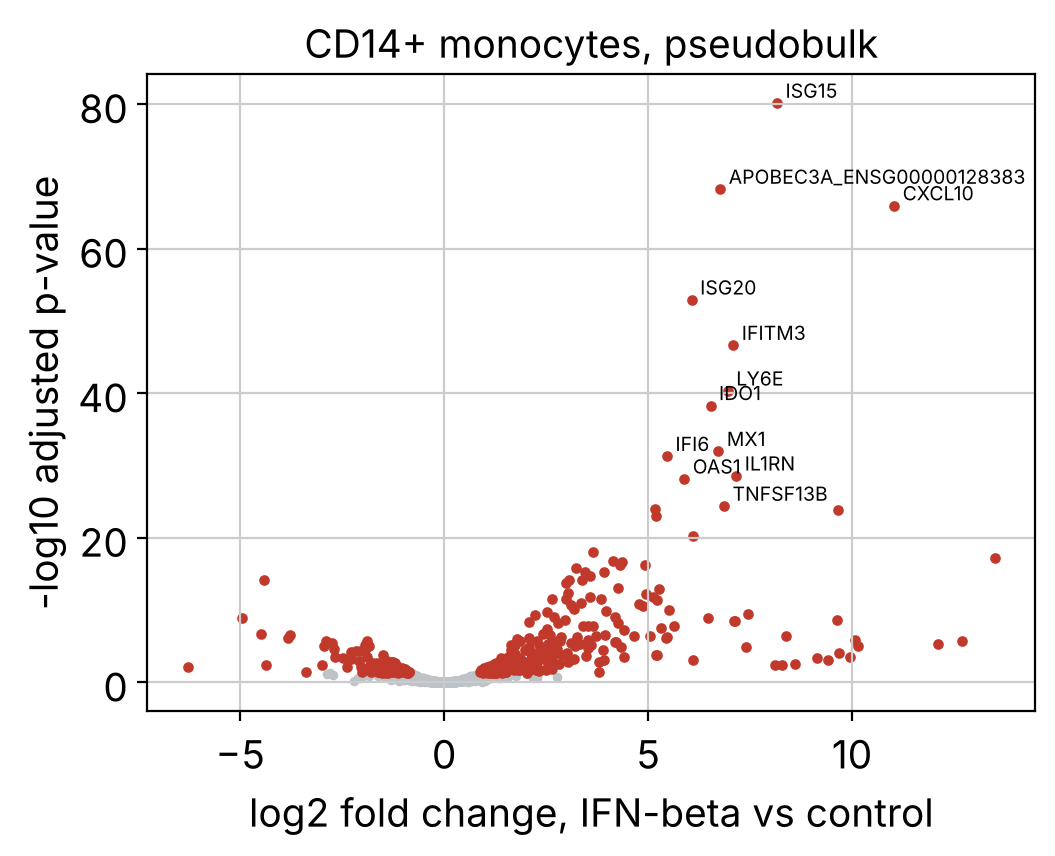

In [18]:
mono = de[(de["cell_type"] == "CD14+ Monocytes") & de["padj"].notna()].copy()
mono["neglog10"] = -np.log10(mono["padj"].clip(lower=1e-300))
fig, ax = plt.subplots(figsize=(5.5, 4.5))
sig = mono["padj"] < 0.05
ax.scatter(mono.loc[~sig, "log2FoldChange"], mono.loc[~sig, "neglog10"], s=6, c="#BDC3C7")
ax.scatter(mono.loc[sig, "log2FoldChange"], mono.loc[sig, "neglog10"], s=8, c="#C0392B")
for _, r in mono.sort_values("padj").head(12).iterrows():
    ax.annotate(r["gene"], (r["log2FoldChange"], r["neglog10"]), fontsize=7, xytext=(3, 2), textcoords="offset points")
ax.set_xlabel("log2 fold change, IFN-beta vs control")
ax.set_ylabel("-log10 adjusted p-value")
ax.set_title("CD14+ monocytes, pseudobulk")
plt.tight_layout()
plt.savefig(FIG / "volcano_cd14_monocytes.png", dpi=150)
plt.show()

## Summary

Without integration, IFN-beta stimulation dominates the embedding and cells separate by condition; after Harmony integration across samples, clustering and marker-based annotation recover the published cell types. Every cell type mounts a strong interferon response, visible in the interferon-stimulated gene score and in the pseudobulk analysis, in which canonical interferon-stimulated genes such as ISG15, IFI6, IFIT3, and MX1 rise sharply in all populations, while monocytes show the broadest response. The pseudobulk approach keeps the sample, not the cell, as the unit of replication, so the reported false discovery rates reflect variation between donors rather than the much smaller variation between cells.

**Reference.** Kang, H. M., Subramaniam, M., Targ, S., et al. (2018). Multiplexed droplet single-cell RNA-sequencing using natural genetic variation. *Nature Biotechnology, 36*, 89–94.

In [19]:
import importlib.metadata as md
for pkg in ["scanpy", "anndata", "harmonypy", "pydeseq2", "numpy", "pandas", "scikit-learn", "leidenalg"]:
    print(pkg, md.version(pkg))

scanpy 1.11.5
anndata 0.13.4
harmonypy 2.1.0
pydeseq2 0.6.0
numpy 2.5.3
pandas 3.0.5
scikit-learn 1.9.1
leidenalg 0.12.0
